# 03 — Variabilidade em escala: curvas de luz do ZTF

Workshop SAB — AI-Scope / ADSS

**Pergunta científica:** como passar de uma seleção espacial para comportamento temporal sem baixar uma base inteira de séries temporais?

`public.ztf_dr22` armazena `hmjd`, `mag`, `magerr` e `catflags` como arrays. O objetivo é selecionar fontes no servidor e transformar apenas as séries retornadas em uma representação adequada para análise temporal.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import adss

BASE_URL = "https://ai-scope.cbpf.br/"

cl = adss.ADSSClient(base_url=BASE_URL)

In [5]:
targets = pd.read_csv("outputs/cluster_1.csv")

In [13]:
query = f"""
SELECT 
    u.source_id AS input_source_id,
    u.ra AS input_ra,
    u.dec AS input_dec,
    d.*,
    dist(u.ra, u.dec, d.ra, d.dec) AS sep
FROM upload.targets AS u
JOIN public.ztf_dr22 AS d
ON cone(d.ra, d.dec, u.ra, u.dec, 0.0002)
"""

ztf = cl.query_and_wait(query_text=query, mode="astroql", file=targets, table_name="targets").data
ztf[["id", "ra", "dec", "filterid", "nepochs"]].head()

Check query status at: https://ai-scope.cbpf.br/queries/198bd72f-ec29-47c5-9c0b-cdb8d3b8a054
Results fetched.


,id,ra,dec,filterid,nepochs
0,442112200001030,323.32413,-0.880697,1,373
1,442312200001023,323.32413,-0.880689,3,119
2,442212200000792,323.32413,-0.880687,2,457
3,442112200001408,323.21660,-0.901997,1,377
4,442312200015397,323.21660,-0.901996,3,121


In [14]:
ztf

,input_source_id,input_ra,input_dec,id,filterid,fieldid,rcid,ra,dec,nepochs,hmjd,mag,magerr,clrcoeff,catflags,sep
0,2686840521431628288,323.324139,-0.880722,442112200001030,1,442,45,323.32413,-0.880697,373,"[58259.42234, 58263.46217, 58267.46232, 58270....","[17.709858, 17.799461, 17.794247, 17.79792, 17...","[0.024854422, 0.025991142, 0.025922375, 0.0259...","[-0.024291513, -0.031033766, -0.006885711, -0....","[32768, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0.000028
1,2686840521431628288,323.324139,-0.880722,442312200001023,3,442,45,323.32413,-0.880689,119,"[58280.3816, 58285.46411, 58289.34133, 58295.3...","[17.07361, 17.062164, 17.048685, 17.0538, 17.0...","[0.021347115, 0.02122703, 0.02108735, 0.021140...","[0.18187469, 0.18810104, 0.1808515, 0.18663082...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.000035
2,2686840521431628288,323.324139,-0.880722,442212200000792,2,442,45,323.32413,-0.880687,457,"[58256.48912, 58259.46288, 58267.40076, 58270....","[17.263308, 17.243483, 17.24369, 17.305132, 17...","[0.020963494, 0.020772744, 0.020774722, 0.0213...","[0.10244724, 0.10916297, 0.10546427, 0.1027833...","[0, 0, 32768, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0.000036
3,2686842033259327104,323.216615,-0.902025,442112200001408,1,442,45,323.21660,-0.901997,377,"[58259.42235, 58263.46218, 58267.46233, 58270....","[18.06142, 18.152874, 18.129597, 18.092577, 18...","[0.029901013, 0.0314976, 0.031078842, 0.030430...","[-0.024291513, -0.031033766, -0.006885711, -0....","[32768, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0.000028
4,2686842033259327104,323.216615,-0.902025,442312200015397,3,442,45,323.21660,-0.901996,121,"[58280.38161, 58285.46412, 58289.34134, 58295....","[17.401611, 17.425165, 17.367685, 17.3908, 17....","[0.02542043, 0.025764968, 0.02493743, 0.025264...","[0.18187469, 0.18810104, 0.1808515, 0.18663082...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.000029
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,2686890343051497344,323.139072,-0.840369,441209100010459,2,441,32,323.13907,-0.840324,407,"[58247.47354, 58254.48214, 58257.41941, 58257....","[17.123962, 17.102821, 17.09687, 17.145443, 17...","[0.01737412, 0.017217005, 0.017173411, 0.01753...","[0.10916272, 0.110453025, 0.10591477, 0.109708...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0.000045
888,2686841041125826432,323.358808,-0.852396,1487207400011740,2,1487,27,323.35880,-0.852390,45,"[58362.38957, 58443.08387, 58773.28351, 58773....","[14.681161, 14.666832, 14.595101, 14.680785, 1...","[0.0170461, 0.01703973, 0.01701011, 0.01704593...","[0.100904085, 0.09805811, 0.10289045, 0.094202...","[0, 1, 32768, 0, 0, 0, 0, 0, 0, 0, 0, 32768, 3...",0.000015
889,2686841041125826432,323.358808,-0.852396,442112200009411,1,442,45,323.35880,-0.852371,369,"[58259.42234, 58263.46217, 58267.46231, 58270....","[15.366209, 15.382106, 15.393857, 15.42044, 15...","[0.013909088, 0.013922329, 0.013932352, 0.0139...","[-0.024291513, -0.031033766, -0.006885711, -0....","[32768, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0.000029
890,2686841041125826432,323.358808,-0.852396,442212200011946,2,442,45,323.35880,-0.852360,459,"[58256.48912, 58259.46287, 58267.40076, 58270....","[14.681878, 14.659246, 14.697509, 14.678854, 1...","[0.011956687, 0.01194491, 0.011965085, 0.01195...","[0.10244724, 0.10916297, 0.10546427, 0.1027833...","[0, 0, 32768, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0.000038


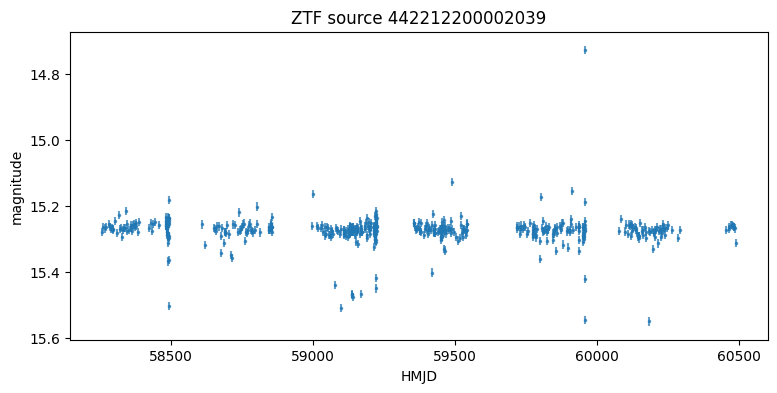

In [15]:
# Escolha uma fonte bem amostrada
row = ztf.sort_values("nepochs", ascending=False).iloc[0]
t = np.asarray(row.hmjd, dtype=float)
m = np.asarray(row.mag, dtype=float)
e = np.asarray(row.magerr, dtype=float)
valid = np.isfinite(t) & np.isfinite(m) & np.isfinite(e)

fig, ax = plt.subplots(figsize=(9,4))
ax.errorbar(t[valid], m[valid], yerr=e[valid], fmt=".", ms=3, alpha=0.7)
ax.invert_yaxis()
ax.set(xlabel="HMJD", ylabel="magnitude", title=f"ZTF source {row.id}")
plt.show()

Candidate period: 0.15081 d


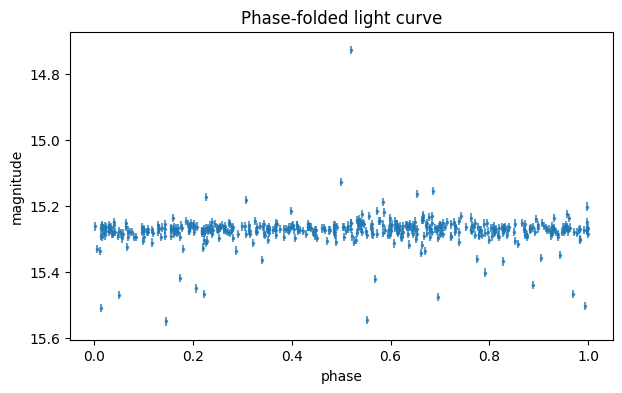

In [16]:
from astropy.timeseries import LombScargle

frequency, power = LombScargle(t[valid], m[valid], e[valid]).autopower(
    minimum_frequency=1/100,
    maximum_frequency=10,
)
best_frequency = frequency[np.argmax(power)]
best_period = 1 / best_frequency
print(f"Candidate period: {best_period:.5f} d")

phase = (t[valid] % best_period) / best_period
fig, ax = plt.subplots(figsize=(7,4))
ax.errorbar(phase, m[valid], yerr=e[valid], fmt=".", ms=3, alpha=0.7)
ax.invert_yaxis()
ax.set(xlabel="phase", ylabel="magnitude", title="Phase-folded light curve")
plt.show()

### Extensão inovadora
Em vez de classificar cada curva diretamente, construa *features* (amplitude robusta, período, entropia, assimetria, dispersão) para centenas de objetos e procure *outliers*. O objetivo passa a ser **descoberta de comportamento raro**, e não reprodução de classes conhecidas.

In [17]:
def variability_features(row):
    m = np.asarray(row.mag, dtype=float)
    m = m[np.isfinite(m)]
    if len(m) < 10:
        return pd.Series({"amp90": np.nan, "std": np.nan, "mad": np.nan})
    med = np.median(m)
    return pd.Series({
        "amp90": np.percentile(m, 95) - np.percentile(m, 5),
        "std": np.std(m),
        "mad": np.median(np.abs(m-med)),
    })

features = pd.concat([ztf[["id","ra","dec","nepochs"]], ztf.apply(variability_features, axis=1)], axis=1)
features.sort_values("amp90", ascending=False).head(15)

,id,ra,dec,nepochs,amp90,std,mad
465,442112200015869,323.42337,-0.831388,320,1.173731,0.382586,0.209204
13,1487107400008962,323.34457,-0.804650,40,0.933255,0.299375,0.041374
505,1487107400008140,323.45398,-0.762592,49,0.732656,0.238144,0.131431
760,1487107400014641,323.35740,-0.769797,49,0.718554,0.194685,0.025696
464,1487207400026370,323.42340,-0.831412,47,0.699461,0.233656,0.216561
432,442112200008915,323.38150,-0.822923,293,0.648427,0.224529,0.195472
321,442212200000347,323.36533,-0.856988,438,0.593203,0.199449,0.078906
614,1487207400025208,323.39706,-0.772032,50,0.560952,0.175809,0.116428
545,442112200022017,323.38434,-0.841524,360,0.559114,0.186935,0.168874
304,1487207400025803,323.34410,-0.800919,44,0.557696,0.192994,0.100874
